# Neural Networks 1 — Neurons, Layers & Loss

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ujjwal091/ai-ml-course/blob/main/modules/04-neural-networks/neural-networks-1/notes.ipynb)

*A neural network is a stack of small units that each do one simple thing. This notebook builds it from the
bottom: one neuron, then layers, then the pieces that let a network learn (activations and loss). We only
cover the **forward pass** — how a trained network makes a prediction. How the weights are found (training)
comes next.*


## 1. A dataset that breaks the models we know

Here is a classic hard shape: **three spiral arms**, one class per arm. Each arm winds around the centre, so the
classes are tangled into each other. (This data is generated, because spirals are a standard test for "can the
model draw a curved boundary?")


In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier


def make_spiral(n_per_arm=300, arms=3, turns=1.6, noise=0.12, seed=0):
    rng = np.random.default_rng(seed)
    X, y = [], []
    for k in range(arms):
        radius = np.linspace(0.2, 1.0, n_per_arm)
        start = k * 2 * np.pi / arms
        angle = np.linspace(start, start + turns * 2 * np.pi, n_per_arm) + rng.normal(0, noise, n_per_arm)
        X.append(np.c_[radius * np.cos(angle), radius * np.sin(angle)] + rng.normal(0, 0.03, (n_per_arm, 2)))
        y += [k] * n_per_arm
    return np.vstack(X), np.array(y)


X, y = make_spiral()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
print(f"{len(X)} points, {len(set(y))} classes, {len(X_train)} for training and {len(X_test)} for testing")

900 points, 3 classes, 630 for training and 270 for testing


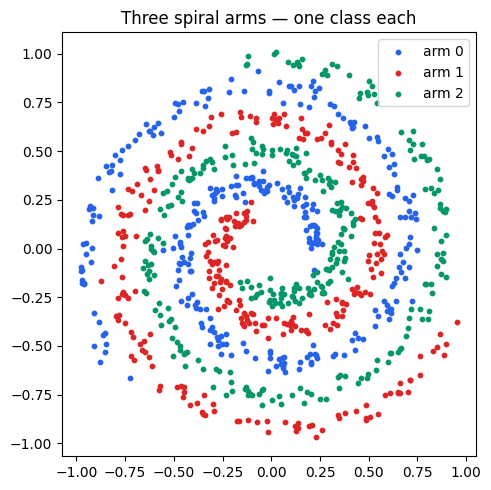

In [2]:
fig, ax = plt.subplots(figsize=(5.2, 5))
for k, color in zip(range(3), ["#2563EB", "#DC2626", "#059669"]):
    ax.scatter(X[y == k, 0], X[y == k, 1], s=10, color=color, label=f"arm {k}")
ax.set_title("Three spiral arms — one class each")
ax.set_aspect("equal")
ax.legend()
plt.tight_layout()
plt.show()

Now try the models we already know. Same two features, no special preparation.


In [3]:
classical = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
    "Decision Tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=0),
    "KNN (k=1)": KNeighborsClassifier(n_neighbors=1),
    "KNN (k=15)": KNeighborsClassifier(n_neighbors=15),
}

rows = []
for name, model in classical.items():
    model.fit(X_train, y_train)
    rows.append((name, model.score(X_train, y_train), model.score(X_test, y_test)))

# A neural network with two hidden layers of 64 neurons each. (How it learns comes in the next notebook.)
mlp = MLPClassifier(hidden_layer_sizes=(64, 64), activation="relu", max_iter=5000, random_state=0)
mlp.fit(X_train, y_train)
rows.append(("Neural network (64 → 64)", mlp.score(X_train, y_train), mlp.score(X_test, y_test)))

pd.DataFrame(rows, columns=["model", "train accuracy", "test accuracy"]).round(3)

,model,train accuracy,test accuracy
0,Logistic Regression,0.405,0.444
1,Linear SVM,0.408,0.444
2,Decision Tree (depth 4),0.457,0.419
3,KNN (k=1),1.000,0.985
4,KNN (k=15),0.924,0.926
5,Neural network (64 → 64),0.998,0.989


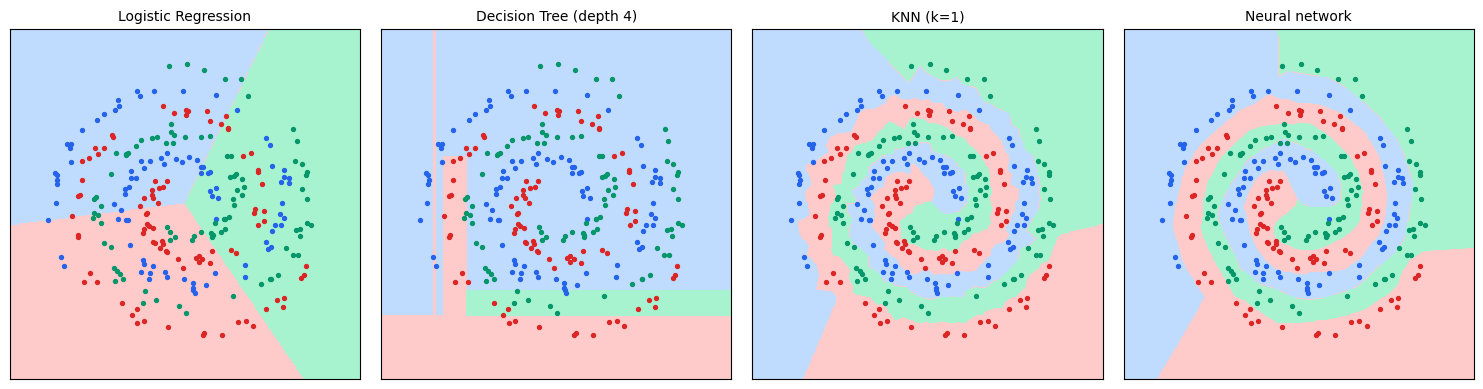

In [4]:
def plot_boundary(ax, model, title):
    xx, yy = np.meshgrid(np.linspace(-1.25, 1.25, 300), np.linspace(-1.25, 1.25, 300))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5, 2.5], colors=["#BFDBFE", "#FECACA", "#A7F3D0"])
    for k, color in zip(range(3), ["#2563EB", "#DC2626", "#059669"]):
        ax.scatter(X_test[y_test == k, 0], X_test[y_test == k, 1], s=8, color=color)
    ax.set_title(title, fontsize=10)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
plot_boundary(axes[0], classical["Logistic Regression"], "Logistic Regression")
plot_boundary(axes[1], classical["Decision Tree (depth 4)"], "Decision Tree (depth 4)")
plot_boundary(axes[2], classical["KNN (k=1)"], "KNN (k=1)")
plot_boundary(axes[3], mlp, "Neural network")
plt.tight_layout()
plt.show()

What the table and the pictures say:

- **Logistic Regression and Linear SVM** are stuck near 0.4. With three classes, guessing gives 0.33. Their
  boundaries are straight lines, and no straight line can separate spirals. This is **underfitting**: the model
  is too simple for the pattern.
- **The shallow decision tree** is no better. Its boundary is made of rectangles that only follow the axes.
- **KNN** does well here, and we should be honest about it: on a small 2-D problem it is hard to beat. But
  it works by *keeping every training point* and looking up neighbours at prediction time. k=1 scores a perfect
  1.0 on training data because each point is its own nearest neighbour. That is memorizing, not learning a rule.
- **The neural network** draws a smooth curved boundary that follows the arms, and it does this with a fixed set
  of numbers (its weights). Add a million more training points and the network stays the same size. KNN would
  have to keep all of them.

A score near chance means the model is *too simple* for the shape — it does not mean we need more data.


## 2. Where neural networks are already used

- **Perception** — face unlock, photo search, voice assistants.
- **Generation** — chat assistants, coding assistants, image and video tools.
- **Decisions at scale** — ranking, fraud detection, credit risk, recommendations.
- **Agents** — multi-step systems built from the same units, wired and prompted differently.

Why not just keep inventing features by hand, like we did in the earlier notebooks? Because it does not scale to raw
pixels, audio or free text. Nobody can hand-write the right features for a photograph. A network learns its own
features straight from the raw data.


## 3. The single neuron

An artificial neuron is borrowed from the shape of a real one: take several inputs, weigh how much each one
matters, add them up, and decide.

1. **Weighted sum:** $z = w_1 x_1 + w_2 x_2 + \dots + b = \mathbf{w} \cdot \mathbf{x} + b$
2. **Squash with the sigmoid:** $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ — this turns any number into a value between 0 and 1,
   which we read as a probability.

The numbers $w$ are the **weights** (how much each input matters, and in which direction). The number $b$ is the
**bias** (the neuron's starting lean before it sees any input).

To see this on real data, we use the **Breast Cancer Wisconsin** dataset that ships with scikit-learn: 569 patients,
with measurements taken from images of cell nuclei. We keep two measurements, `mean radius` and `mean texture`, and
predict whether the tumor is malignant (1) or benign (0). *This is for learning only, not medical advice.*


In [5]:
cancer = load_breast_cancer(as_frame=True).frame
features = ["mean radius", "mean texture"]

tumor_X = cancer[features]
tumor_y = (cancer["target"] == 0).astype(int)  # in this dataset target 0 means malignant, so 1 = malignant here

scaler = StandardScaler().fit(tumor_X)
tumor_Xs = scaler.transform(tumor_X)  # put both features on the same scale (see the Feature Scaling notebook)

print(f"{len(cancer)} patients, {tumor_y.mean():.0%} malignant")
tumor_X.describe().loc[["mean", "std", "min", "max"]].round(2)

569 patients, 37% malignant


,mean radius,mean texture
mean,14.13,19.29
std,3.52,4.30
min,6.98,9.71
max,28.11,39.28


Here is a neuron written from scratch. It has no learning in it yet. It just takes weights and a bias and
computes the output.


In [6]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


class Neuron:
    def __init__(self, weights, bias):
        self.weights = np.array(weights, dtype=float)
        self.bias = float(bias)

    def process(self, x):
        z = np.dot(self.weights, x) + self.bias   # step 1: weighted sum
        return sigmoid(z), z                      # step 2: squash into 0..1


# Weights chosen by hand for now: a bigger radius pushes toward malignant, texture pushes a little too
neuron = Neuron(weights=[3.0, 1.0], bias=-0.5)

for i in [0, 1, 19, 100, 300]:
    p, z = neuron.process(tumor_Xs[i])
    print(f"patient {i:>3}: radius={cancer.loc[i, 'mean radius']:>5.2f}  texture={cancer.loc[i, 'mean texture']:>5.2f}"
          f"  z={z:>6.2f}  P(malignant)={p:.3f}  actual={'malignant' if tumor_y[i] else 'benign'}")

patient   0: radius=17.99  texture=10.38  z=  0.72  P(malignant)=0.672  actual=malignant
patient   1: radius=20.57  texture=17.77  z=  4.64  P(malignant)=0.990  actual=malignant
patient  19: radius=13.54  texture=14.36  z= -2.15  P(malignant)=0.105  actual=benign
patient 100: radius=13.61  texture=24.98  z=  0.38  P(malignant)=0.595  actual=malignant
patient 300: radius=19.53  texture=18.90  z=  4.01  P(malignant)=0.982  actual=malignant


Read one line: a large radius gives a large positive $z$, the sigmoid turns that into a probability close to 1.
A small radius gives a negative $z$ and a probability close to 0. Values of $z$ near 0 give a probability near 0.5,
which means "the neuron is unsure".

**The bias** moves the decision point without looking at the inputs. Without it, a neuron would always say
exactly 0.5 when every input is zero, and every boundary would pass through the origin. A very negative bias makes
the neuron cautious: it needs strong evidence before it says "malignant".


In [7]:
print("Same patients, same weights — but with the bias changed from -0.5 to -5:")
cautious = Neuron(weights=[3.0, 1.0], bias=-5.0)
for i in [0, 1, 19, 100, 300]:
    print(f"  patient {i:>3}: before={neuron.process(tumor_Xs[i])[0]:.3f}   after={cautious.process(tumor_Xs[i])[0]:.3f}")

Same patients, same weights — but with the bias changed from -0.5 to -5:
  patient   0: before=0.672   after=0.022
  patient   1: before=0.990   after=0.534
  patient  19: before=0.105   after=0.001
  patient 100: before=0.595   after=0.016
  patient 300: before=0.982   after=0.381


**A warning about signs.** The sign of a weight is the direction of its effect. If we flip the sign of the radius
weight, nothing crashes. The neuron simply believes that *bigger tumors are safer*, and it says so with
confidence:


In [8]:
flipped = Neuron(weights=[-3.0, 1.0], bias=-0.5)
for i in [0, 1, 300]:
    print(f"  patient {i:>3} (actually malignant): P(malignant) = {flipped.process(tumor_Xs[i])[0]:.3f}")

  patient   0 (actually malignant): P(malignant) = 0.003
  patient   1 (actually malignant): P(malignant) = 0.002
  patient 300 (actually malignant): P(malignant) = 0.006


Wrong weights fail silently and confidently. There is no error message. This is why we will always check a model's
output against data and not trust the code just because it runs.


## 4. A neuron *is* logistic regression

This is the most important idea in the notebook. Train scikit-learn's `LogisticRegression` on the same data. Then
copy its learned weights and bias into our `Neuron`. If a neuron really is logistic regression, the two should give
the same probabilities.


In [9]:
log_reg = LogisticRegression().fit(tumor_Xs, tumor_y)
learned = Neuron(weights=log_reg.coef_[0], bias=log_reg.intercept_[0])

print("learned weights:", log_reg.coef_[0].round(3), " bias:", log_reg.intercept_[0].round(3))

ours = np.array([learned.process(x)[0] for x in tumor_Xs])
theirs = log_reg.predict_proba(tumor_Xs)[:, 1]
print("largest difference over all 569 patients:", np.abs(ours - theirs).max())

learned weights: [3.336 0.877]  bias: -0.699
largest difference over all 569 patients: 2.220446049250313e-16


The difference is about $10^{-16}$, which is just floating-point rounding. They are the same thing.

So **logistic regression is a neural network with one neuron and no hidden layers**. The unit we are about to
stack is not new. The power comes from composing many of them, not from changing the unit.


## 5. From one neuron to a network

- **One neuron** makes one yes/no decision.
- **Many neurons in one layer** each look for a different pattern in the same inputs.
- **Several layers** let each layer make the next layer's job easier. The first layer's outputs become the next
  layer's inputs. Step by step, a straight-line boundary gets bent into a spiral.

Here is a small network: 2 inputs, a hidden layer of 4 neurons, a hidden layer of 3, and 3 outputs (one per class).


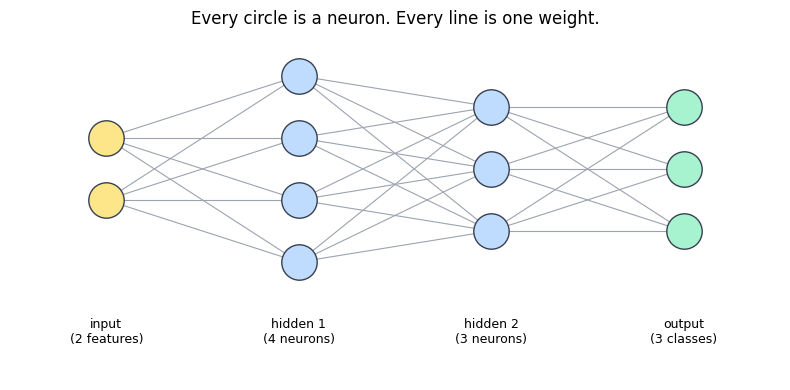

In [10]:
layer_sizes = [2, 4, 3, 3]
layer_names = ["input\n(2 features)", "hidden 1\n(4 neurons)", "hidden 2\n(3 neurons)", "output\n(3 classes)"]
fig, ax = plt.subplots(figsize=(8, 4))
positions = []
for li, size in enumerate(layer_sizes):
    ys = np.linspace(-(size - 1) / 2, (size - 1) / 2, size)
    positions.append([(li, yv) for yv in ys])
for li in range(len(layer_sizes) - 1):
    for (x1, y1) in positions[li]:
        for (x2, y2) in positions[li + 1]:
            ax.plot([x1, x2], [y1, y2], color="#9CA3AF", lw=0.8, zorder=1)
for li, layer in enumerate(positions):
    color = ["#FDE68A", "#BFDBFE", "#BFDBFE", "#A7F3D0"][li]
    for (xv, yv) in layer:
        ax.scatter(xv, yv, s=650, color=color, edgecolor="#374151", zorder=2)
    ax.text(li, -2.4, layer_names[li], ha="center", va="top", fontsize=9)
ax.set_xlim(-0.5, 3.5)
ax.set_ylim(-3.4, 2.2)
ax.axis("off")
ax.set_title("Every circle is a neuron. Every line is one weight.")
plt.tight_layout()
plt.show()

### Layers are matrix multiplication

Writing a loop over every neuron and every sample would be slow. Instead, we put all the weights of a layer
into one matrix $W$ and do everything in one go:

$$Z = X W + \mathbf{b}$$

- $X$ has shape (samples, inputs)
- $W$ has shape (inputs, neurons) — one column per neuron
- $\mathbf{b}$ has one number per neuron
- $Z$ has shape (samples, neurons) — one answer per sample per neuron

Our trained network from Section 1 already has these matrices. Look at their shapes:


In [11]:
for i, (W, b) in enumerate(zip(mlp.coefs_, mlp.intercepts_), start=1):
    print(f"layer {i}:  W {W.shape}   b {b.shape}   → {W.shape[1]} neurons, each with {W.shape[0]} weights + 1 bias")
print("total numbers the network learned:", sum(W.size + b.size for W, b in zip(mlp.coefs_, mlp.intercepts_)))

layer 1:  W (2, 64)   b (64,)   → 64 neurons, each with 2 weights + 1 bias
layer 2:  W (64, 64)   b (64,)   → 64 neurons, each with 64 weights + 1 bias
layer 3:  W (64, 3)   b (3,)   → 3 neurons, each with 64 weights + 1 bias
total numbers the network learned: 4547


Why bother with matrices? Because CPUs and GPUs have hardware built for exactly this operation. Compare the
same layer computed with plain Python loops and with one matrix multiplication:


In [12]:
rng = np.random.default_rng(0)
X_many = rng.normal(size=(3000, 2))
W1, b1 = mlp.coefs_[0], mlp.intercepts_[0]


def layer_with_loops(X, W, b):
    out = np.zeros((len(X), W.shape[1]))
    for i in range(len(X)):
        for j in range(W.shape[1]):
            total = 0.0
            for k in range(W.shape[0]):
                total += X[i, k] * W[k, j]
            out[i, j] = total + b[j]
    return out


t0 = time.perf_counter()
slow = layer_with_loops(X_many, W1, b1)
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
fast = X_many @ W1 + b1
t_matrix = time.perf_counter() - t0

print(f"loops:  {t_loop:.3f} s")
print(f"matrix: {t_matrix:.5f} s   (≈ {t_loop / t_matrix:,.0f}× faster)")
print("same answer:", np.allclose(slow, fast))

loops:  0.113 s
matrix: 0.00142 s   (≈ 80× faster)
same answer: True


Same numbers, far less time. And this is only a layer with 64 neurons and 2 inputs. Real networks have millions of
weights, so matrix form is what makes training them possible at all.

The price of a bigger network is also real: more neurons and layers mean more memory, more computation, more
delay for each prediction, and more cost.


## 6. Why depth needs activation functions

There is a trap. If every layer is just $XW + b$, stacking layers gains nothing. Two linear layers collapse into
one linear layer:

$$(X W_1) W_2 = X (W_1 W_2)$$

Check it with numbers:


In [13]:
rng = np.random.default_rng(1)
A = rng.normal(size=(5, 2))
W_a = rng.normal(size=(2, 4))
W_b = rng.normal(size=(4, 3))

two_layers = (A @ W_a) @ W_b
one_layer = A @ (W_a @ W_b)
print("two linear layers equal one combined layer:", np.allclose(two_layers, one_layer))

two linear layers equal one combined layer: True


So a "deep" network made only of linear layers is secretly just one linear model. Let's see this on the spiral. We
build the same network (two hidden layers of 64), but ask for the identity activation, which means "do nothing
between layers":


In [14]:
linear_net = MLPClassifier(hidden_layer_sizes=(64, 64), activation="identity", max_iter=5000, random_state=0)
linear_net.fit(X_train, y_train)
print(f"two hidden layers, no real activation:  test accuracy = {linear_net.score(X_test, y_test):.3f}")
print(f"two hidden layers, ReLU activation:     test accuracy = {mlp.score(X_test, y_test):.3f}")

two hidden layers, no real activation:  test accuracy = 0.444
two hidden layers, ReLU activation:     test accuracy = 0.989


Same size, same data. The only difference is the **non-linear activation** between layers. It is what makes depth
useful.

The three common choices:

| Activation | Formula | Output range |
|---|---|---|
| Sigmoid | $\dfrac{1}{1+e^{-z}}$ | 0 to 1 |
| Tanh | $\dfrac{e^z - e^{-z}}{e^z + e^{-z}}$ | −1 to 1 |
| ReLU | $\max(0, z)$ | 0 up to anything |


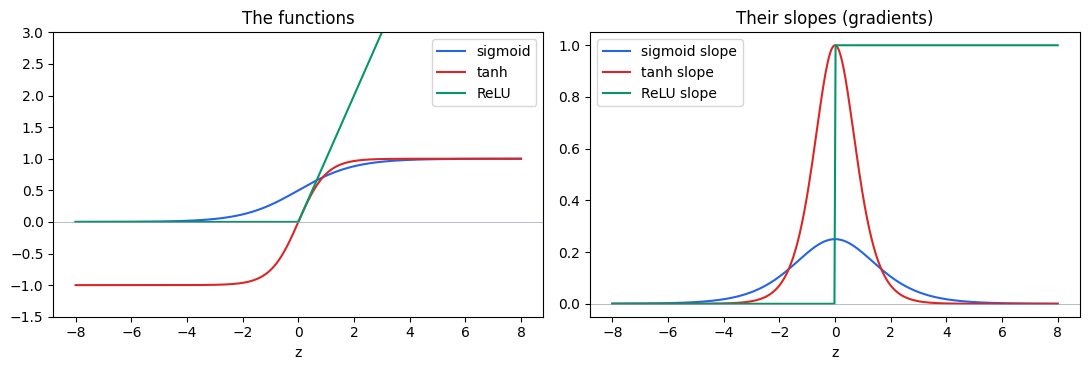

In [15]:
z = np.linspace(-8, 8, 400)
sig = sigmoid(z)
tanh = np.tanh(z)
relu = np.maximum(0, z)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(z, sig, label="sigmoid", color="#2563EB")
axes[0].plot(z, tanh, label="tanh", color="#DC2626")
axes[0].plot(z, relu, label="ReLU", color="#059669")
axes[0].set_ylim(-1.5, 3)
axes[0].set_title("The functions")
axes[0].legend()
axes[1].plot(z, sig * (1 - sig), label="sigmoid slope", color="#2563EB")
axes[1].plot(z, 1 - tanh**2, label="tanh slope", color="#DC2626")
axes[1].plot(z, (z > 0).astype(float), label="ReLU slope", color="#059669")
axes[1].set_title("Their slopes (gradients)")
axes[1].legend()
for a in axes:
    a.set_xlabel("z")
    a.axhline(0, color="#9CA3AF", lw=0.5)
plt.tight_layout()
plt.show()

The right picture matters most. A **gradient** is the slope, and training uses the slope to decide how to change a
weight. When the slope is close to 0, learning stalls. Look at what happens when $z$ is large:


In [16]:
z_big = 6.0
s = sigmoid(z_big)
print(f"at z = {z_big:.0f}:")
print(f"  sigmoid slope = {s * (1 - s):.6f}")
print(f"  tanh slope    = {1 - np.tanh(z_big) ** 2:.6f}")
print(f"  ReLU slope    = {1.0:.6f}")

at z = 6:
  sigmoid slope = 0.002467
  tanh slope    = 0.000025
  ReLU slope    = 1.000000


Sigmoid and tanh **saturate**: far from zero they go flat, so the slope is nearly 0 and the signal to learn almost
disappears. ReLU keeps a slope of exactly 1 for any positive input, and it is also cheap to compute. That is why
**ReLU is the usual choice for hidden layers**.

Two things to keep straight:

- **Sigmoid is not obsolete.** It is still the right choice for the final neuron of a yes/no model, because we
  want a probability from 0 to 1.
- **ReLU is not perfect.** If a neuron's $z$ is negative for every input, its output and slope are both 0 and it
  stops learning. This is called a "dead" neuron. Variants such as GELU and SwiGLU, common in large language
  models, soften this.


## 7. Loss functions: scoring a prediction

To train a network, we need one number that says how wrong a prediction is. That number is the **loss**. Training
tries to make it small. For yes/no problems the standard choice is **binary cross-entropy** (also called log loss):

$$\text{loss} = -\big[\, y \log(p) + (1-y)\log(1-p) \,\big]$$

where $y$ is the true label (0 or 1) and $p$ is the predicted probability of class 1. When the true label is 1, the
formula reduces to $-\log(p)$.


In [17]:
def binary_cross_entropy(y_true, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)   # never let p be exactly 0 or 1, because log(0) is infinite
    return -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))


# A truly malignant tumor (y = 1). What does the loss say as the model gets more wrong?
for p in [0.99, 0.90, 0.50, 0.10, 0.01]:
    print(f"true = malignant, predicted P(malignant) = {p:.2f}  →  loss = {binary_cross_entropy(1, p):.4f}")

true = malignant, predicted P(malignant) = 0.99  →  loss = 0.0101
true = malignant, predicted P(malignant) = 0.90  →  loss = 0.1054
true = malignant, predicted P(malignant) = 0.50  →  loss = 0.6931
true = malignant, predicted P(malignant) = 0.10  →  loss = 2.3026
true = malignant, predicted P(malignant) = 0.01  →  loss = 4.6052


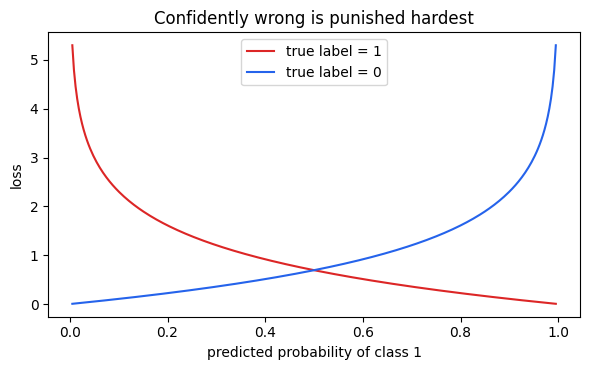

In [18]:
p_axis = np.linspace(0.005, 0.995, 300)
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(p_axis, binary_cross_entropy(1, p_axis), color="#DC2626", label="true label = 1")
ax.plot(p_axis, binary_cross_entropy(0, p_axis), color="#2563EB", label="true label = 0")
ax.set_xlabel("predicted probability of class 1")
ax.set_ylabel("loss")
ax.set_title("Confidently wrong is punished hardest")
ax.legend()
plt.tight_layout()
plt.show()

Predicting 0.90 for a true "1" costs only 0.105. Predicting 0.10 costs 2.303, about 22 times more. The loss
climbs steeply as the model becomes confidently wrong, and those are the dangerous mistakes.

**Class imbalance.** In the cancer data, 37% of patients are malignant. In a fraud dataset it might be 0.1%.
A model that always says "not fraud" would score 99.9% accuracy and be useless. Weighted cross-entropy handles
this by making mistakes on the rare class cost more.

### Why not just use squared error?

Mean squared error works for regression, and you might try it here. The problem is the slope. Let's compare how
strongly each loss pushes on $z$ (the neuron's raw score) when the true label is 1:

- cross-entropy: $\;p - 1$
- squared error: $\;2(p-1)\,p\,(1-p)$


In [19]:
print("true label = 1.   How hard does each loss push on z?")
print(f"{'predicted p':>12} {'cross-entropy':>15} {'squared error':>15}")
for p in [0.01, 0.10, 0.50, 0.90]:
    print(f"{p:>12.2f} {p - 1:>15.4f} {2 * (p - 1) * p * (1 - p):>15.4f}")

true label = 1.   How hard does each loss push on z?
 predicted p   cross-entropy   squared error
        0.01         -0.9900         -0.0196
        0.10         -0.9000         -0.1620
        0.50         -0.5000         -0.2500
        0.90         -0.1000         -0.0180


Look at the first row. The model is 99% sure of the wrong answer. Cross-entropy pushes hard (−0.99). Squared
error barely pushes (−0.02) because the sigmoid is flat out there, so the model learns slowest exactly when it
is most wrong. Cross-entropy also matches maximum likelihood: it is the natural score for "how likely were the
true labels under my model?"

### The `log(0)` trap

If the model outputs exactly 0 for a true "1", then $-\log(0) = \infty$, and the infinity becomes `NaN` once it flows
into later calculations. That is the usual reason a loss suddenly turns into `NaN` in the middle of training.
This is why the function above clips the probability:


In [20]:
with np.errstate(divide="ignore"):
    print("without clipping:", -np.log(0.0))
print("with clipping at 1e-12:", round(float(binary_cross_entropy(1, 0.0)), 3))

without clipping: inf
with clipping at 1e-12: 27.631


## 8. Softmax and more than two classes

With three classes (like our spiral, or the three iris species) the network ends with 3 output neurons. Each
produces a raw score called a **logit**. We need to turn these three scores into three probabilities that add up
to 1. That is what **softmax** does:

$$\text{softmax}(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

Let's use the real **Iris** data (150 flowers, 3 species, 4 measurements). We fit a plain multi-class logistic
regression, take its raw scores for a few flowers, and apply softmax ourselves.


In [21]:
iris = load_iris()
iris_X = StandardScaler().fit_transform(iris.data)
iris_y = iris.target
iris_model = LogisticRegression(max_iter=1000).fit(iris_X, iris_y)


def softmax_naive(logits):
    e = np.exp(logits)
    return e / e.sum(axis=1, keepdims=True)


picked = [0, 70, 134]   # one flower from each species
logits = iris_X[picked] @ iris_model.coef_.T + iris_model.intercept_
probs = softmax_naive(logits)

print("species:", iris.target_names)
print("logits:\n", logits.round(2))
print("probabilities:\n", probs.round(3))
print("rows add up to:", probs.sum(axis=1))
print("matches scikit-learn:", np.allclose(probs, iris_model.predict_proba(iris_X[picked])))

species: ['setosa' 'versicolor' 'virginica']
logits:
 [[ 6.91  2.75 -9.67]
 [-2.47  1.13  1.35]
 [-4.26  2.04  2.22]]
probabilities:
 [[0.985 0.015 0.   ]
 [0.012 0.44  0.548]
 [0.001 0.455 0.544]]
rows add up to: [1. 1. 1.]
matches scikit-learn: True


Softmax is again not new: it is exactly what scikit-learn's multi-class model does at its last step.

### A numerical trap: overflow

$e^{1000}$ is too big for a computer number, so it becomes `inf`, and `inf / inf` is `NaN`:


In [22]:
big_logits = np.array([[1000.0, 1001.0, 1002.0]])
with np.errstate(over="ignore", invalid="ignore"):
    print("naive softmax: ", softmax_naive(big_logits))

naive softmax:  [[nan nan nan]]


The fix is simple. Softmax does not change if you subtract the same number from every logit, so subtract the largest
one first. The biggest value becomes 0, so the biggest exponent is $e^0 = 1$ and nothing overflows. The answer is
mathematically identical.


In [23]:
def softmax(logits):
    shifted = logits - logits.max(axis=1, keepdims=True)   # the max-subtraction trick
    e = np.exp(shifted)
    return e / e.sum(axis=1, keepdims=True)


print("stable softmax:", softmax(big_logits))
print("same as before on normal numbers:", np.allclose(softmax(logits), softmax_naive(logits)))

stable softmax: [[0.09003057 0.24472847 0.66524096]]
same as before on normal numbers: True


### Multi-class cross-entropy

The loss for one sample is just $-\log$ of the probability given to the **true** class. The other probabilities
do not enter the formula directly (they matter because all probabilities add to 1). Using the three flowers above:


In [24]:
true_labels = iris_y[picked]
rows = []
for k, i in enumerate(picked):
    p_true = probs[k, true_labels[k]]
    rows.append({
        "flower": i,
        "true species": iris.target_names[true_labels[k]],
        "predicted": iris.target_names[probs[k].argmax()],
        "P(true species)": p_true,
        "loss = -log(P)": -np.log(p_true),
    })
loss_table = pd.DataFrame(rows)
print(loss_table.round(4).to_string(index=False))
print(f"\naverage loss over the batch: {loss_table['loss = -log(P)'].mean():.4f}")

 flower true species predicted  P(true species)  loss = -log(P)
      0       setosa    setosa           0.9847          0.0154
     70   versicolor virginica           0.4398          0.8214
    134    virginica virginica           0.5441          0.6087

average loss over the batch: 0.4818


A flower that gets a high probability for its true species has a tiny loss. Flower 70 is a versicolor that the
model thinks is slightly more likely virginica (0.55 against 0.44), so it is wrong and pays a bigger loss. The
average of the per-sample losses is the number training tries to push down.


## 9. Putting it together: a forward pass from scratch

We now have every piece: matrix layers, ReLU in the middle, softmax at the end. Let's write the network's forward
pass ourselves, using only the weights that scikit-learn learned in Section 1, and check that we get the same
predictions as `mlp.predict_proba`.


In [25]:
def relu(z):
    return np.maximum(0, z)


class ForwardNetwork:
    """Runs a trained network: ReLU after every hidden layer, softmax at the end."""

    def __init__(self, weights, biases):
        self.weights = weights
        self.biases = biases

    def forward(self, X):
        a = X
        for W, b in zip(self.weights[:-1], self.biases[:-1]):
            a = relu(a @ W + b)                          # hidden layer: matrix multiply, then ReLU
        logits = a @ self.weights[-1] + self.biases[-1]  # last layer: raw scores
        return softmax(logits)                           # raw scores → probabilities


net = ForwardNetwork(mlp.coefs_, mlp.intercepts_)
our_probs = net.forward(X_test)

print("shape of the output:", our_probs.shape, "(one row per test point, one column per class)")
print("matches scikit-learn:", np.allclose(our_probs, mlp.predict_proba(X_test)))
print("largest difference:", np.abs(our_probs - mlp.predict_proba(X_test)).max())
print(f"accuracy from our own forward pass: {(our_probs.argmax(axis=1) == y_test).mean():.3f}")

shape of the output: (270, 3) (one row per test point, one column per class)
matches scikit-learn: True


largest difference: 0.0
accuracy from our own forward pass: 0.989


That is a complete neural network prediction in about ten lines. A tiny sample, followed layer by layer:


In [26]:
point = X_test[:1]
print("input point:", point.round(3))
a1 = relu(point @ mlp.coefs_[0] + mlp.intercepts_[0])
print("after hidden layer 1:", a1.shape, f"— {int((a1 > 0).sum())} of {a1.shape[1]} neurons are active (non-zero)")
a2 = relu(a1 @ mlp.coefs_[1] + mlp.intercepts_[1])
print("after hidden layer 2:", a2.shape, f"— {int((a2 > 0).sum())} of {a2.shape[1]} neurons are active")
out = softmax(a2 @ mlp.coefs_[2] + mlp.intercepts_[2])
print("output probabilities:", out.round(3), "→ class", out.argmax(), "(true class:", y_test[0], ")")

input point: [[-0.188  0.117]]
after hidden layer 1: (1, 64) — 31 of 64 neurons are active (non-zero)
after hidden layer 2: (1, 64) — 34 of 64 neurons are active
output probabilities: [[0.005 0.995 0.   ]] → class 1 (true class: 1 )


Notice that many neurons output exactly 0 for a given input: ReLU switches them off. Each input lights up a
different subset of neurons, and that changing pattern is how a network builds a curved boundary out of
straight pieces.

What we did *not* cover: where those weights came from. Our `mlp` was trained by scikit-learn behind the scenes.
Finding good weights means measuring the loss (Section 7), working out which way to nudge each weight, and
repeating. That is **backpropagation and optimization**, the next notebook.


## 10. Summary — revision cheat sheet

- Models with straight or blocky boundaries **underfit** a spiral. KNN can fit it but keeps every training point.
  A network learns a fixed set of weights instead.
- **Neuron** = weighted sum $z = \mathbf{w}\cdot\mathbf{x} + b$, then an activation (sigmoid for a probability).
- **Bias** shifts the decision point; **weight signs** are the direction of each input's effect. Wrong signs fail
  silently.
- **A neuron is logistic regression.** One neuron, no hidden layers. Power comes from stacking.
- **A layer is one matrix multiplication:** $Z = XW + b$. Shapes: $X$ (samples, inputs), $W$ (inputs, neurons).
  Matrix form is hundreds of times faster than loops.
- **Linear layers collapse into one.** A non-linear activation between layers is what makes depth useful.
- **Sigmoid and tanh saturate** (slope ≈ 0 when $|z|$ is large). **ReLU** has slope 1 for positive inputs, so it is the
  default for hidden layers. Dead neurons are its weakness. Sigmoid is still right for a yes/no output.
- **Binary cross-entropy** punishes confident wrong answers hard and keeps strong gradients. Clip probabilities
  so $\log(0)$ never happens.
- **Softmax** turns logits into probabilities that add to 1. Subtract the max logit first to avoid overflow.
- **Multi-class cross-entropy** = $-\log$(probability of the true class), averaged over the batch.
- A **forward pass** is: repeat (matrix multiply → activation), then softmax. About ten lines of NumPy.

**Quick self-check**

1. What is a single neuron in terms of a model you already know? *(Logistic regression.)*
2. What does the bias do? *(Shifts where the neuron switches from "no" to "yes", independent of the inputs.)*
3. A layer has 5 inputs and 4 neurons. What shape is $W$? *(5 × 4.)*
4. Why can't we stack linear layers and call it deep? *(They collapse into one linear layer.)*
5. Why does ReLU train better than sigmoid in hidden layers? *(Slope stays 1 for positive inputs; sigmoid goes flat.)*
6. What do we subtract inside softmax, and why? *(The largest logit, to prevent overflow; the answer is unchanged.)*
7. A loss turns into `NaN` mid-training. What is a likely cause? *(A probability hit 0 inside the log.)*

**Next**: backpropagation and optimization — how the weights are found.
